# 01 - EDA: Smart Student Study Planner
Goal: load the data, inspect its structure, build a data dictionary, check data quality.

In [1]:
import pandas as pd

df = pd.read_csv("../data/student-mat.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
df.shape

(395, 33)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [4]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [5]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
zero_g3 = df[df["G3"] == 0]
print("Rows with G3 = 0:", len(zero_g3))
print("Percentage:", round(len(zero_g3) / len(df) * 100, 1), "%")

Rows with G3 = 0: 38
Percentage: 9.6 %


In [8]:
# Do the zero-grade students look different?
df.assign(is_zero=df["G3"] == 0).groupby("is_zero")[["absences", "failures", "studytime"]].mean()

,absences,failures,studytime
is_zero,,,
False,6.316527,0.271709,2.042017
True,0.000000,0.921053,1.973684


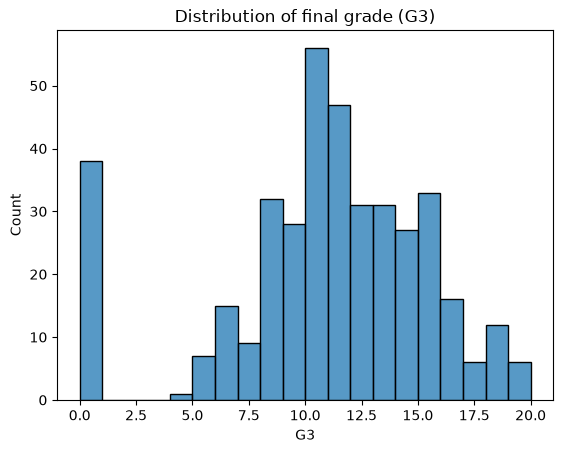

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df["G3"], bins=20)
plt.title("Distribution of final grade (G3)")
plt.xlabel("G3")
plt.show()

In [10]:
df[["G1", "G2", "G3"]].dtypes

G1    int64
G2    int64
G3    int64
dtype: object

| Column | Type | Meaning | Known at planning time? |
|---|---|---|---|
| school | binary | School (GP or MS) | Yes |
| sex | binary | Student's sex | Yes |
| age | numeric | Age (15 to 22) | Yes |
| address | binary | Urban or rural home | Yes |
| famsize | binary | Family size (up to 3, or more than 3) | Yes |
| Pstatus | binary | Parents living together or apart | Yes |
| Medu | ordinal | Mother's education (0 to 4) | Yes |
| Fedu | ordinal | Father's education (0 to 4) | Yes |
| Mjob | categorical | Mother's job | Yes |
| Fjob | categorical | Father's job | Yes |
| reason | categorical | Reason for choosing the school | Yes |
| guardian | categorical | Main guardian | Yes |
| traveltime | ordinal | Home-to-school travel time (1 to 4) | Yes |
| studytime | ordinal | Weekly study time (1 to 4) | Yes |
| failures | numeric | Number of past class failures | Yes |
| schoolsup | binary | Extra educational support from school | Yes |
| famsup | binary | Family educational support | Yes |
| paid | binary | Extra paid classes in the subject | Yes |
| activities | binary | Extracurricular activities | Yes |
| nursery | binary | Attended nursery school | Yes |
| higher | binary | Wants higher education | Yes |
| internet | binary | Internet access at home | Yes |
| romantic | binary | In a romantic relationship | Yes |
| famrel | ordinal | Family relationship quality (1 to 5) | Yes |
| freetime | ordinal | Free time after school (1 to 5) | Yes |
| goout | ordinal | Going out with friends (1 to 5) | Yes |
| Dalc | ordinal | Weekday alcohol use (1 to 5) | Yes |
| Walc | ordinal | Weekend alcohol use (1 to 5) | Yes |
| health | ordinal | Current health status (1 to 5) | Yes |
| absences | numeric | Number of school absences | Judgement call |
| G1 | numeric | First period grade (0 to 20) | No (excluded) |
| G2 | numeric | Second period grade (0 to 20) | No (excluded) |
| G3 | numeric | Final grade (0 to 20) | Target |